# 04 - Clustering: user archetypes (Question 1)

**Question:** can we discover distinct types of FriendFeed users from how they publish, interact and connect?

**Input:** `data/user_features.parquet` - 201,335 users × 15 features.
**Goal of this notebook**:
1. Address **correlated features**.
2. Choose **k** with evidence (SSE, silhouette).
3. Check **stability** across random initialisations and agreement with a **second algorithm** (Ward hierarchical clustering).
4. Describe, name and save the final clusters.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

ROOT = Path.cwd().parent
OUT, FIG = ROOT / "data", ROOT / "figures"
FIG.mkdir(exist_ok=True)

BLUE, MUTED = "#2a78d6", "#898781"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9, "axes.titlesize": 11})

df = pd.read_parquet(OUT / "user_features.parquet")
df.shape

(201335, 15)

Loading the user feature table (**201,335 users × 15 features**) and the new tools used for this notebook: 
`AgglomerativeClustering` / `linkage` (hierarchical clustering), `adjusted_rand_score` (compares two clusterings) and `silhouette_samples` (silhouette per point, so it can be averaged per cluster).

### PCA as a diagnostic: which features are redundant?

In [2]:
COUNTS = ["n_posts", "n_sources", "n_comments_on_others", "n_comments_on_own", "n_comments_received",
          "n_likes_given", "n_likes_received", "n_followers", "n_following", "n_services"]
SHARES = ["pct_native", "pct_image", "pct_video"]

X13  = pd.concat([np.log1p(df[COUNTS]), df[SHARES]], axis=1)
Xs13 = StandardScaler().fit_transform(X13)

pca = PCA().fit(Xs13)
print("cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_).round(2))

loadings = pd.DataFrame(pca.components_[:2].T, index=X13.columns, columns=["PC1", "PC2"]).round(2)
loadings.sort_values("PC1", ascending=False)

cumulative explained variance: [0.35 0.52 0.62 0.7  0.78 0.84 0.89 0.92 0.95 0.97 0.99 0.99 1.  ]


,PC1,PC2
n_comments_received,0.43,-0.12
n_likes_received,0.43,-0.09
n_comments_on_others,0.42,-0.16
n_likes_given,0.42,-0.13
n_comments_on_own,0.35,0.04
n_following,0.18,0.29
n_posts,0.17,0.28
n_sources,0.17,0.41
n_followers,0.17,0.43
pct_native,0.17,-0.38


**Findings - PCA as a diagnostic**

PCA builds new uncorrelated axes as linear combinations of the features, ordered by how much variance they capture. Here it is used to **find redundant features**, not as clustering input.

- **PC1 (35% of the variance) is the "interaction" component:** the four interaction features load almost equally (comments received 0.43, likes received 0.43, comments on others 0.42, likes given 0.42); everything else is small. PC1 is essentially their sum - these four features carry largely the same information.
- **PC2 (17%) is an "automation / reach" component:** services +0.51, followers +0.43, sources +0.41, pct_native -0.38.
- 9 components are needed for 95% of the variance - the features describe several different properties, not just one.

**Why PCA alone does not fix the correlation problem:** PCA only rotates the data. Keeping (almost) all components leaves the distances between users (almost) unchanged, so k-means would give the same result and interaction would still dominate.

### Feature construction: one interaction index instead of four correlated features

In [3]:
df["n_interaction"] = (df["n_comments_on_others"] + df["n_comments_received"]
                       + df["n_likes_given"] + df["n_likes_received"])

FEATS  = ["n_posts", "n_sources", "n_interaction", "n_comments_on_own",
          "n_followers", "n_following", "n_services"]
SHARES = ["pct_native", "pct_image", "pct_video"]

X  = pd.concat([np.log1p(df[FEATS]), df[SHARES]], axis=1)
Xs = StandardScaler().fit_transform(X)

corr = X.corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("feature matrix:", X.shape)
pairs.sort_values(key=abs, ascending=False).head(5).round(2)

feature matrix: (201335, 10)


n_followers    n_following    0.62
n_sources      n_services     0.54
n_posts        n_sources      0.49
n_interaction  pct_native     0.49
n_followers    n_services     0.41
dtype: float64

**Findings – one interaction index**

- `n_interaction` = comments on others + comments received + likes given + likes received = all interaction with other people. "Interaction" now counts **once** in the Euclidean distance instead of four times.
- `n_comments_on_own` stays separate: commenting on one's own posts is not interaction with others and correlates less with the other four.
- New feature matrix: **10 features** (7 log-transformed counts + 3 shares), z-scored.
- Remaining strongest Spearman correlations: followers - following **0.62**, sources - services 0.54, posts - sources 0.49, interaction - pct_native 0.49; the 0.67–0.76 correlations are gone.
- **Followers ↔ following (0.62) is kept on purpose:** they mean different things - an influential account has many followers, a follow-spam bot follows huge numbers of accounts. Merging them would hide exactly that difference.

### Choosing k: SSE and silhouette, before vs after merging

features,"10 features, interaction merged",13 features (notebook 03)
k,,
2,0.214,0.673
3,0.192,0.192
4,0.219,0.220
5,0.245,0.246
6,0.272,0.270
7,0.228,0.220
8,0.231,0.223


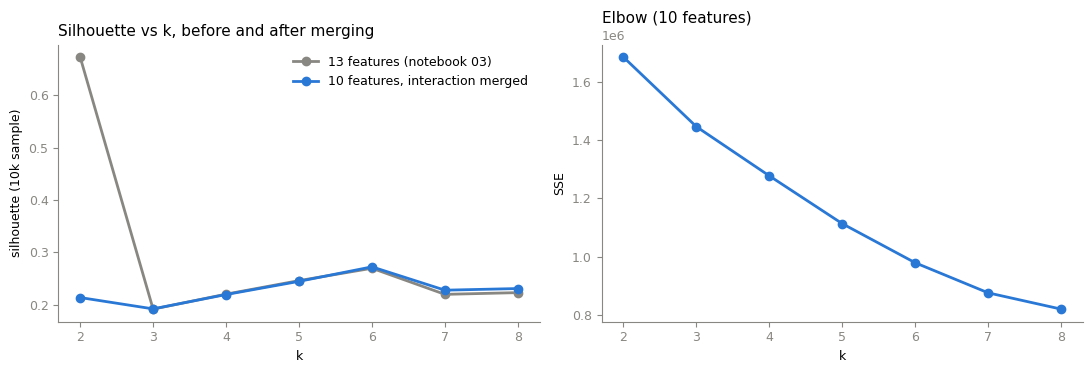

In [4]:
rng = np.random.default_rng(42)
sample = rng.choice(len(Xs), 10000, replace=False)

rows = []
for name, data in [("13 features (notebook 03)", Xs13), ("10 features, interaction merged", Xs)]:
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data)
        rows.append((name, k, km.inertia_, silhouette_score(data[sample], km.labels_[sample])))
res = pd.DataFrame(rows, columns=["features", "k", "sse", "silhouette"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, g), color in zip(res.groupby("features", sort=False), [MUTED, BLUE]):
    axes[0].plot(g["k"], g["silhouette"], marker="o", linewidth=2, color=color, label=name)
new = res[res["features"].str.startswith("10")]
axes[1].plot(new["k"], new["sse"], marker="o", linewidth=2, color=BLUE)
axes[0].set_xlabel("k"); axes[0].set_ylabel("silhouette (10k sample)"); axes[0].legend(frameon=False)
axes[0].set_title("Silhouette vs k, before and after merging", loc="left")
axes[1].set_xlabel("k"); axes[1].set_ylabel("SSE"); axes[1].set_title("Elbow (10 features)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "07_choose_k_after.png", dpi=150)

res.pivot(index="k", columns="features", values="silhouette").round(3)

**Findings - choosing k, before vs after merging**

| k | 2 | 3 | 4 | 5 | **6** | 7 | 8 |
|---|---|---|---|---|---|---|---|
| silhouette, 13 features (notebook 03) | 0.673 | 0.192 | 0.220 | 0.246 | 0.270 | 0.220 | 0.223 |
| silhouette, 10 features (merged) | 0.214 | 0.192 | 0.219 | 0.245 | **0.272** | 0.228 | 0.231 |

- **The misleading k = 2 peak disappears (0.67 - 0.21).** It came from interaction being counted four times, which made "interacts vs does not" an artificially strong split.
- **k = 6 has the highest silhouette (0.272)** among the meaningful solutions.
- The SSE curve has **no clear elbow**, so silhouette decides k.
- Silhouettes around 0.2–0.3 are **modest**: clusters exist but boundaries are soft - the data is partly a continuum. 

*Silhouette of a point:* s = (b − a) / max(a, b), with a = mean distance to its own cluster, b = mean distance to the nearest other cluster; close to 1 = well placed, 0 = on a border, < 0 = probably misassigned. Computed on a 10,000-user sample because it needs all pairwise distances (O(n²)).

### Stability: do different random starts give the same clusters?

In [5]:
stab = []
for k in (4, 5, 6):
    labels = [KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(Xs) for seed in range(5)]
    aris = [adjusted_rand_score(labels[0], l) for l in labels[1:]]
    stab.append((k, round(min(aris), 3), round(np.mean(aris), 3)))
pd.DataFrame(stab, columns=["k", "min ARI vs seed 0", "mean ARI vs seed 0"])

,k,min ARI vs seed 0,mean ARI vs seed 0
0,4,0.974,0.979
1,5,0.989,0.995
2,6,0.993,0.998


**Findings – stability across random initialisations**

k-means starts from random centroids and can end in different local minima. Here it is rerun with 5 different random seeds and each result is compared with seed 0 using the **Adjusted Rand Index (ARI)**.

*ARI:* the Rand statistic counts the share of point pairs on which two clusterings agree (same cluster in both, or different clusters in both). ARI corrects it for chance: **1 = identical clusterings, ≈ 0 = no more agreement than random**. It does not depend on the cluster numbers (cluster 2 in one run may be cluster 5 in another).

| k | min ARI | mean ARI |
|---|---|---|
| 4 | 0.974 | 0.979 |
| 5 | 0.989 | 0.995 |
| **6** | **0.993** | **0.998** |

- All solutions are very stable; **k = 6 is the most stable** - the six clusters are not an accident of the random start.

### Second algorithm: Ward hierarchical clustering on a sample

   k  ARI k-means vs Ward
0  4                0.413
1  5                0.441
2  6                0.536


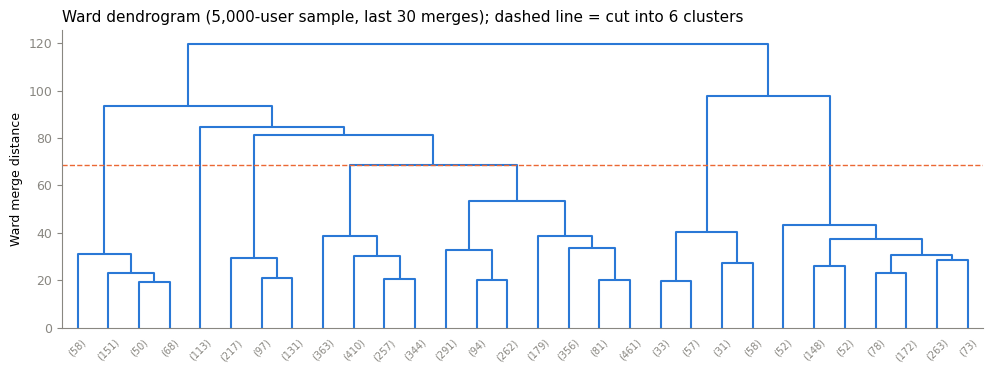

In [6]:
S = rng.choice(len(Xs), 5000, replace=False)          # hierarchical clustering needs all pairwise distances

agree = []
for k in (4, 5, 6):
    km_labels   = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
    ward_labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xs[S])
    agree.append((k, round(adjusted_rand_score(km_labels[S], ward_labels), 3)))
print(pd.DataFrame(agree, columns=["k", "ARI k-means vs Ward"]))

Z = linkage(Xs[S], method="ward")
fig, ax = plt.subplots(figsize=(10, 3.8))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=0, above_threshold_color=BLUE,
           show_leaf_counts=True, leaf_font_size=7)
ax.axhline(Z[-6, 2], color="#eb6834", linestyle="--", linewidth=1)
ax.set_ylabel("Ward merge distance")
ax.set_title("Ward dendrogram (5,000-user sample, last 30 merges); dashed line = cut into 6 clusters", loc="left")
fig.tight_layout(); fig.savefig(FIG / "08_ward_dendrogram.png", dpi=150)

**Findings – agreement with a second algorithm (Ward hierarchical clustering)**

*Ward's method* (agglomerative): starts with every user as its own cluster and repeatedly merges the two clusters whose merge increases the total within-cluster squared error (SSE) the least - the same objective as k-means, but built bottom-up and without random starts. It needs all pairwise distances (O(n²) memory), so it runs on a **random sample of 5,000 users**; its labels are compared with the k-means labels of the same users.

| k | ARI k-means vs Ward |
|---|---|
| 4 | 0.41 |
| 5 | 0.44 |
| **6** | **0.54** |

- **k = 6 gives the best agreement** between the two algorithms - a third independent argument for k = 6 (besides silhouette and stability).
- Agreement is **moderate, not perfect**: the clearest groups (e.g. conversationalists, media sharers) are found by both; the boundaries between the large automated groups depend on the algorithm - consistent with the modest silhouette.
- **Dendrogram**: the height of each merge = how much the SSE increases. Large jumps near the top mean well-separated groups; the dashed line marks the cut that gives 6 clusters.

### Final model: k-means with k = 6, cluster profiles

In [7]:
K = 6
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
df["cluster"] = km.labels_

profile = df.groupby("cluster")[FEATS + SHARES].median().round(2)
profile["has_description"] = df.groupby("cluster")["has_description"].mean().round(2)
profile.insert(0, "n_users", df["cluster"].value_counts().sort_index())
profile.insert(1, "pct_users", (profile["n_users"] / len(df) * 100).round(1))

sil = silhouette_samples(Xs[sample], km.labels_[sample])
profile["silhouette"] = pd.Series(sil).groupby(km.labels_[sample]).mean().round(2)
profile.T

cluster,0,1,2,3,4,5
n_users,98509.00,6504.00,7010.00,60487.00,15808.00,13017.00
pct_users,48.90,3.20,3.50,30.00,7.90,6.50
n_posts,6.00,59.00,3.00,26.00,4.00,3.00
n_sources,1.00,3.50,1.00,3.00,2.00,1.00
n_interaction,0.00,148.00,0.00,0.00,0.00,0.00
n_comments_on_own,0.00,34.00,0.00,0.00,0.00,0.00
n_followers,8.00,138.00,13.00,83.00,12.00,2.00
n_following,5.00,119.00,5.00,36.00,5.00,7.00
n_services,2.00,4.00,5.00,6.00,4.00,0.00
pct_native,0.00,0.52,0.00,0.00,0.00,1.00


**Findings - the final model: k-means, k = 6** (medians per cluster; silhouette = mean per cluster on the 10k sample)

| Cluster | Users | % | Posts | Interaction | Native | Image | Video | Services | Followers | Following | Silhouette |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 98,509 | 48.9 | 6 | 0 | 0.00 | 0.00 | 0 | 2 | 8 | 5 | 0.33 |
| 1 | 6,504 | 3.2 | 59 | **148** | 0.52 | 0.25 | 0 | 4 | **138** | **119** | 0.29 |
| 2 | 7,010 | 3.5 | 3 | 0 | 0.00 | 0.00 | **1.00** | 5 | 13 | 5 | **0.45** |
| 3 | 60,487 | 30.0 | **26** | 0 | 0.00 | 0.01 | 0 | **6** | 83 | 36 | 0.12 |
| 4 | 15,808 | 7.9 | 4 | 0 | 0.00 | **0.92** | 0 | 4 | 12 | 5 | 0.32 |
| 5 | 13,017 | 6.5 | 3 | 0 | **1.00** | 0.00 | 0 | **0** | 2 | 7 | 0.35 |

- Medians (not means): within each cluster the counts are still skewed, so the median describes the typical member; values are in original units.
- **Best-separated cluster:** video sharers (silhouette 0.45). **Weakest:** cluster 3 (0.12) - it overlaps with its neighbours (it sits between the low-activity users and the conversationalists).
- `has_description` (share of users with a profile text, not used in clustering): highest among cluster 1 (71%), lowest among the media-sharing clusters (19%) - supports the reading of cluster 1 as engaged humans and clusters 2/4 as automated feeds.

### Naming the clusters from their profiles

In [8]:
def name_cluster(p):
    if p["n_interaction"] > 0:   return "Conversationalists"
    if p["pct_video"] >= 0.5:    return "Video sharers"
    if p["pct_image"] >= 0.5:    return "Image sharers"
    if p["pct_native"] >= 0.5:   return "Native casual users"
    if p["n_followers"] >= 50:   return "Cross-posting broadcasters"
    return "Low-activity automated posters"

names = profile.apply(name_cluster, axis=1)
df["archetype"] = df["cluster"].map(names)

summary = profile[["n_users", "pct_users", "n_posts", "n_interaction", "pct_native", "pct_image",
                   "pct_video", "n_services", "n_followers", "n_following", "silhouette"]].copy()
summary.insert(0, "archetype", names)
summary.sort_values("n_users", ascending=False)

,archetype,n_users,pct_users,n_posts,n_interaction,pct_native,pct_image,pct_video,n_services,n_followers,n_following,silhouette
cluster,,,,,,,,,,,,
0,Low-activity automated posters,98509,48.9,6.0,0.0,0.00,0.00,0.0,2.0,8.0,5.0,0.33
3,Cross-posting broadcasters,60487,30.0,26.0,0.0,0.00,0.01,0.0,6.0,83.0,36.0,0.12
4,Image sharers,15808,7.9,4.0,0.0,0.00,0.92,0.0,4.0,12.0,5.0,0.32
5,Native casual users,13017,6.5,3.0,0.0,1.00,0.00,0.0,0.0,2.0,7.0,0.35
2,Video sharers,7010,3.5,3.0,0.0,0.00,0.00,1.0,5.0,13.0,5.0,0.45
1,Conversationalists,6504,3.2,59.0,148.0,0.52,0.25,0.0,4.0,138.0,119.0,0.29


**Findings – the six archetypes**

Names are assigned from each cluster's profile (rules in `name_cluster`, checked in order):

| Archetype | Share | What characterises it |
|---|---|---|
| **Low-activity automated posters** | 48.9% | few posts (median 6), all through external tools (0% native), ~2 services, few followers, no interaction |
| **Cross-posting broadcasters** | 30.0% | many posts (26) from several sources, the most linked services (6), many followers (83) - but never interact; content is pushed in automatically, with wide reach |
| **Image sharers** | 7.9% | 92% of posts contain an image (e.g. photo feeds such as Flickr), automated, no interaction |
| **Native casual users** | 6.5% | everything typed directly on FriendFeed (100% native), but very little (3 posts), no linked services, few followers |
| **Video sharers** | 3.5% | every post contains a video (e.g. YouTube favourites feeds), automated, no interaction |
| **Conversationalists** | 3.2% | the only group that interacts (median 148 comments/likes), half native posting, most followers (138) and following (119) |

**Answer to Question 1:** yes - six distinct, interpretable user types exist. The platform is dominated by **automated publishing** (≈ 90% of posting users publish through external tools and never interact); genuine **conversation is concentrated in ~3% of users**. Media feeds (images, videos) form their own groups.
- silhouettes 0.12–0.45 - the archetypes describe tendencies with soft boundaries, not sharp classes.

### Visualising the clusters: profile heatmap and PCA projection

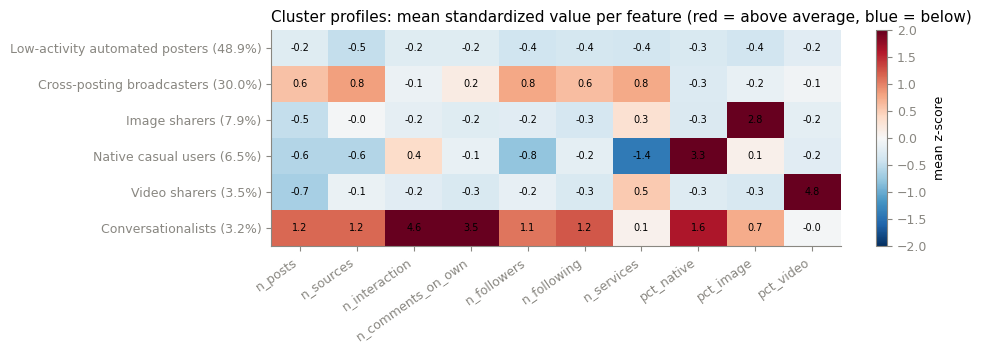

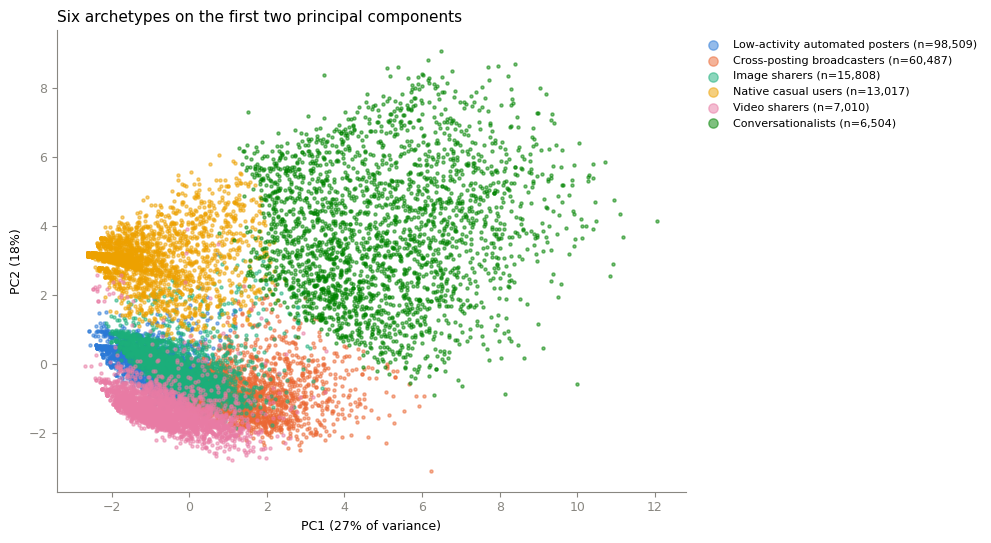

In [9]:
order = summary.sort_values("n_users", ascending=False).index
z = pd.DataFrame(Xs, columns=X.columns).groupby(df["cluster"].values).mean().loc[order]

fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(z.shape[1])); ax.set_xticklabels(z.columns, rotation=35, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels([f"{names[c]} ({summary.loc[c, 'pct_users']}%)" for c in order])
for i in range(K):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="mean z-score")
ax.set_title("Cluster profiles: mean standardized value per feature (red = above average, blue = below)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "09_cluster_profiles.png", dpi=150)

pca10 = PCA(n_components=2).fit(Xs); P = pca10.transform(Xs)
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, c in enumerate(order):
    idx = np.where(df["cluster"].values == c)[0]
    idx = rng.choice(idx, min(2500, len(idx)), replace=False)
    ax.scatter(P[idx, 0], P[idx, 1], s=5, alpha=0.5, color=CLUSTER_COLORS[i],
               label=f"{names[c]} (n={summary.loc[c, 'n_users']:,})")
ax.set_xlabel(f"PC1 ({pca10.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca10.explained_variance_ratio_[1]:.0%})")
ax.legend(frameon=False, markerscale=3, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Six archetypes on the first two principal components", loc="left")
fig.tight_layout(); fig.savefig(FIG / "10_pca_clusters_k6.png", dpi=150)

**Findings - visualisations**

**Profile heatmap**: each cell = the cluster's mean **z-score** on a feature (0 = average user, +1 = one standard deviation above, red above / blue below average). It shows each archetype's signature at a glance: conversationalists +4.6 on interaction, image sharers +2.8 on pct_image, video sharers +4.8 on pct_video, native casual users +3.3 on pct_native and −1.4 on services, broadcasters above average on posts, sources, followers and services.

**PCA projection**: the 10 features projected on the first two principal components (PC1 27% + PC2 18% = 45% of the variance - 55% is not shown). Conversationalists separate clearly; the automated groups lie close together and partly overlap in 2D, consistent with the silhouette values. At most 2,500 points per cluster are drawn to avoid over-plotting.

### Save the cluster labels

In [10]:
df[["user_id", "cluster", "archetype"]].to_parquet(OUT / "user_clusters.parquet", index=False)
df["archetype"].value_counts()

archetype
Low-activity automated posters    98509
Cross-posting broadcasters        60487
Image sharers                     15808
Native casual users               13017
Video sharers                      7010
Conversationalists                 6504
Name: count, dtype: int64

**Output:** `data/user_clusters.parquet` - one row per user with `user_id`, `cluster` and `archetype`. It can be joined to posts in later analysis (e.g. which archetypes' posts receive comments).

**Summary of decisions in this notebook**
1. Correlated interaction features (ρ 0.67 - 0.76, PCA PC1) - merged into one constructed feature.
2. k chosen by three independent criteria - all point to **k = 6**: best silhouette (0.272), most stable across seeds (ARI ≥ 0.99), best agreement with Ward hierarchical clustering (ARI 0.54).
3. Results reported with their limits: modest silhouettes, moderate cross-algorithm agreement - soft boundaries.